In [1]:
from pathlib import Path

import pandas as pd
try:
    from tqdm.auto import tqdm
except ModuleNotFoundError:
    def tqdm(iterable, **kwargs):
        return iterable
from rdkit import Chem
from rdkit.Chem import Draw
from rdkit.Chem.FilterCatalog import FilterCatalog, FilterCatalogParams

In [2]:
# define paths
HERE = Path(_dh[-1])
DATA = HERE / "data"

In [3]:
# load the top 100 compounds from the cluster 6 workflow (step 6 predictions + step 7 docking)
egfr_data = pd.read_csv(HERE / "data/top100_docking_results.csv")

# this file names the identifier column "compound_id"; rename it so the rest of
# the talktorial code (which expects "molecule_chembl_id") works unchanged
egfr_data = egfr_data.rename(columns={"compound_id": "molecule_chembl_id"})

print("Dataframe shape:", egfr_data.shape)
egfr_data.head()

Dataframe shape: (100, 7)


,molecule_chembl_id,smiles,pred_pIC50,pred_IC50_nM,vina_score,ml_rank,docking_rank
0,s_2230__17793196__16949512,CC1=C(C(=O)N2CCCCC2=N1)CCN3CCN(CC3)C4=CC=CC5=C...,7.812313,15.405896,-9.987,1,65
1,s_2230__12304850__16949512,CC1=C(C(=O)N2CCCCC2=N1)CCN3CCN(CC3)C4=CC=CC5=C...,7.784896,16.409822,-10.447,2,40
2,s_2230__665554__16949512,COC1=CC=CC=C1N2CCN(CC2)CCC3=C(N=C4CCCCN4C3=O)C,7.778951,16.636017,-9.283,3,92
3,s_2230__9292524__16949512,CC1=C(C(=O)N2CCCCC2=N1)CCN3CCN(CC3)C4=C(C(=CC=...,7.767475,17.081462,-10.709,4,24
4,s_2230__14934458__16949512,CC1=C(C(=O)N2CCCCC2=N1)CCN3CCN(CC3)C4=C(C(=CC=...,7.729491,18.642729,-10.306,5,48


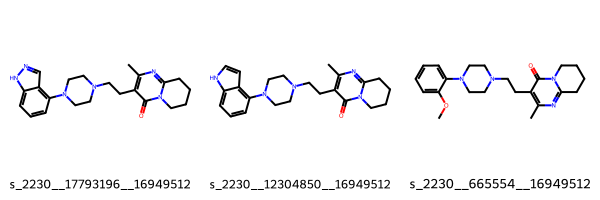

In [4]:
# Draw first 3 molecules
mols = [Chem.MolFromSmiles(smiles) for smiles in egfr_data.head(3)["smiles"]]

Chem.Draw.MolsToGridImage(
    mols,
    legends=list(egfr_data.head(3).molecule_chembl_id),
)

In [5]:
# initialize filter
params = FilterCatalogParams()
params.AddCatalog(FilterCatalogParams.FilterCatalogs.PAINS)
catalog = FilterCatalog(params)

In [6]:
# search for PAINS
matches = []
clean = []
for index, row in tqdm(egfr_data.iterrows(), total=egfr_data.shape[0]):
    molecule = Chem.MolFromSmiles(row.smiles)
    entry = catalog.GetFirstMatch(molecule)  # Get the first matching PAINS
    if entry is not None:
        # store PAINS information
        matches.append(
            {
                "chembl_id": row.molecule_chembl_id,
                "rdkit_molecule": molecule,
                "pains": entry.GetDescription().capitalize(),
            }
        )
    else:
        # collect indices of molecules without PAINS
        clean.append(index)

matches = pd.DataFrame(matches)
egfr_data = egfr_data.loc[clean]  # keep molecules without PAINS

  0%|          | 0/100 [00:00<?, ?it/s]

In [7]:
# NBVAL_CHECK_OUTPUT
print(f"Number of compounds with PAINS: {len(matches)}")
print(f"Number of compounds without PAINS: {len(egfr_data)}")

Number of compounds with PAINS: 1
Number of compounds without PAINS: 99


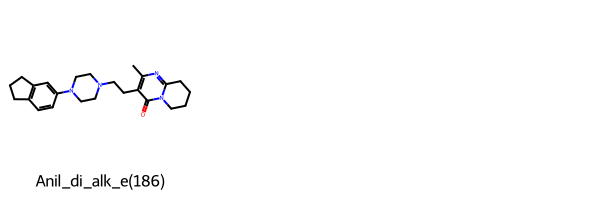

In [8]:
Chem.Draw.MolsToGridImage(
    list(matches.head(3).rdkit_molecule),
    legends=list(matches.head(3)["pains"]),
)

In [9]:
substructures = pd.read_csv(DATA / "unwanted_substructures.csv", sep="\\s+")
substructures["rdkit_molecule"] = substructures.smarts.apply(Chem.MolFromSmarts)
print("Number of unwanted substructures in collection:", len(substructures))
# NBVAL_CHECK_OUTPUT

Number of unwanted substructures in collection: 104


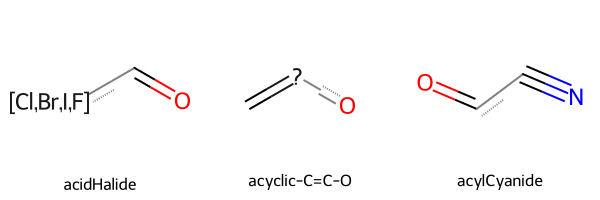

In [10]:
Chem.Draw.MolsToGridImage(
    mols=substructures.rdkit_molecule.tolist()[2:5],
    legends=substructures.name.tolist()[2:5],
)

In [11]:
# search for unwanted substructure
matches = []
clean = []
for index, row in tqdm(egfr_data.iterrows(), total=egfr_data.shape[0]):
    molecule = Chem.MolFromSmiles(row.smiles)
    match = False
    for _, substructure in substructures.iterrows():
        if molecule.HasSubstructMatch(substructure.rdkit_molecule):
            matches.append(
                {
                    "chembl_id": row.molecule_chembl_id,
                    "rdkit_molecule": molecule,
                    "substructure": substructure.rdkit_molecule,
                    "substructure_name": substructure["name"],
                }
            )
            match = True
    if not match:
        clean.append(index)

matches = pd.DataFrame(matches)
egfr_data = egfr_data.loc[clean]

  0%|          | 0/99 [00:00<?, ?it/s]

In [12]:
# NBVAL_CHECK_OUTPUT
print(f"Number of found unwanted substructure: {len(matches)}")
print(f"Number of compounds without unwanted substructure: {len(egfr_data)}")

Number of found unwanted substructure: 8
Number of compounds without unwanted substructure: 91


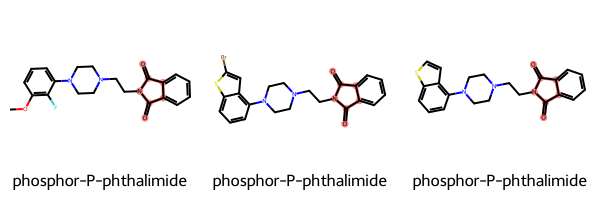

In [13]:
to_highlight = [
    row.rdkit_molecule.GetSubstructMatch(row.substructure) for _, row in matches.head(3).iterrows()
]
Chem.Draw.MolsToGridImage(
    list(matches.head(3).rdkit_molecule),
    highlightAtomLists=to_highlight,
    legends=list(matches.head(3).substructure_name),
)

In [14]:
# NBVAL_CHECK_OUTPUT
groups = matches.groupby("substructure_name")
group_frequencies = groups.size()
group_frequencies.sort_values(ascending=False, inplace=True)
group_frequencies.head(10)

substructure_name
phosphor-P-phthalimide    7
triple-bond               1
dtype: int64